<a href="https://colab.research.google.com/github/EgorMehed/ML-homework/blob/main/%D0%9B%D0%A0_%D0%9A%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D0%9C%D0%B5%D1%85%D0%B5%D0%B4_%D0%84%D0%B3%D0%BE%D1%80_%D0%A4%D0%86%D0%A23_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

**Виконав:** студент групи ФІТ 3-12 Мехед Єгор

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [ ]:
iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
iris_df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

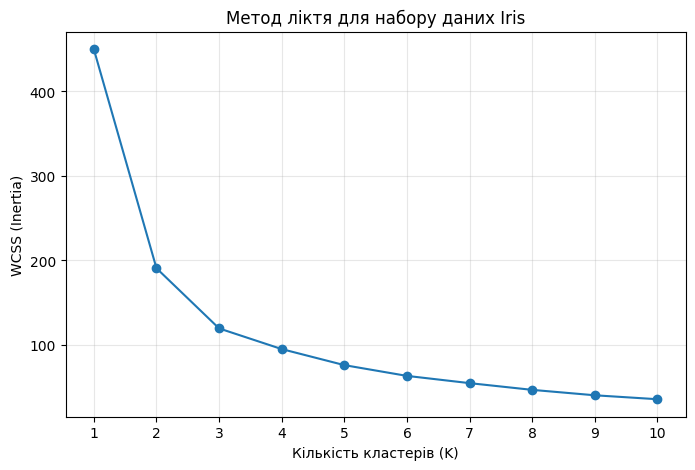

In [ ]:
iris_features = iris_df.iloc[:, :3]
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(iris_features)

wcss_iris = []
k_range_elbow = range(1, 11)
for k in k_range_elbow:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(X_iris_scaled)
    wcss_iris.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range_elbow, wcss_iris, marker='o', linestyle='-')
plt.title('Метод ліктя для набору даних Iris')
plt.xlabel('Кількість кластерів (K)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(k_range_elbow)
plt.grid(True, alpha=0.3)
plt.show()


**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

K = 2: Silhouette Score = 0.5525
K = 3: Silhouette Score = 0.4594
K = 4: Silhouette Score = 0.4057
K = 5: Silhouette Score = 0.3755
K = 6: Silhouette Score = 0.3772
K = 7: Silhouette Score = 0.3628
K = 8: Silhouette Score = 0.3814
K = 9: Silhouette Score = 0.3749
K = 10: Silhouette Score = 0.3791


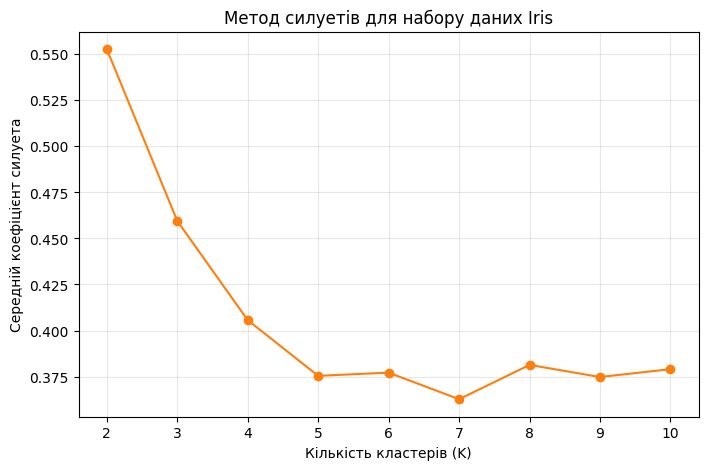

In [ ]:
silhouette_iris = []
k_range_sil = range(2, 11)
for k in k_range_sil:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_iris_scaled)
    score = silhouette_score(X_iris_scaled, labels)
    silhouette_iris.append(score)

for k, s in zip(k_range_sil, silhouette_iris):
    print(f'K = {k}: Silhouette Score = {s:.4f}')

plt.figure(figsize=(8, 5))
plt.plot(k_range_sil, silhouette_iris, marker='o', color='tab:orange')
plt.title('Метод силуетів для набору даних Iris')
plt.xlabel('Кількість кластерів (K)')
plt.ylabel('Середній коефіцієнт силуета')
plt.xticks(k_range_sil)
plt.grid(True, alpha=0.3)
plt.show()


**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

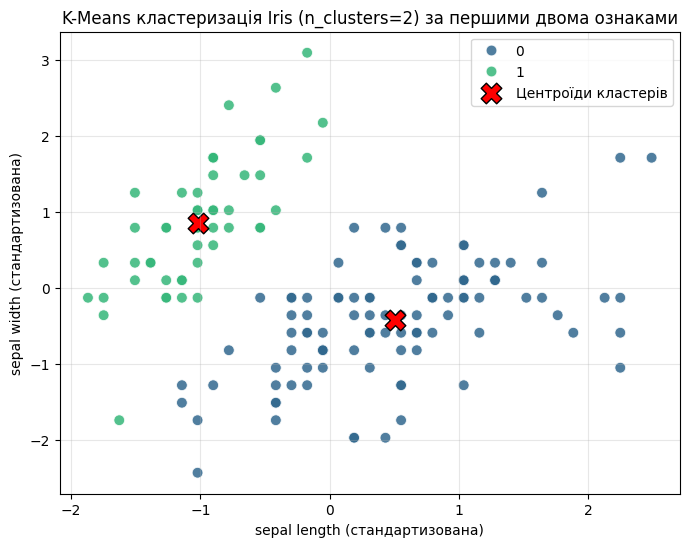

In [ ]:
kmeans_iris_final = KMeans(n_clusters=2, init='k-means++', n_init=10, random_state=42)
clusters_iris = kmeans_iris_final.fit_predict(X_iris_scaled)
centers_iris = kmeans_iris_final.cluster_centers_

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=X_iris_scaled[:, 0],
    y=X_iris_scaled[:, 1],
    hue=clusters_iris,
    palette='viridis',
    s=60,
    alpha=0.85
)
plt.scatter(
    centers_iris[:, 0],
    centers_iris[:, 1],
    c='red',
    marker='X',
    s=220,
    edgecolors='black',
    label='Центроїди кластерів'
)
plt.title('K-Means кластеризація Iris (n_clusters=2) за першими двома ознаками')
plt.xlabel('sepal length (стандартизована)')
plt.ylabel('sepal width (стандартизована)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

**Висновок (Мехед Єгор, ФІТ 3-12):**
За графіком методу ліктя найбільш різке падіння внутрішньокластерної суми квадратів відстаней (WCSS) спостерігається при переході від $K=1$ до $K=2$ та дещо сповільнюється після $K=2\ldots3$. Водночас графік коефіцієнта силуета досягає глобального максимуму саме при **$K=2$** (значення силуета є найвищим серед усіх досліджених $K \in [2; 10]$). Вибір двох кластерів повністю узгоджується з обома графіками й пояснюється природною геометрією даних Iris: один вид ірисів (*Iris setosa*) лінійно та просторово чітко відокремлений від двох інших видів (*Iris versicolor* та *Iris virginica*), які у просторі ознак розташовані близько й утворюють другу спільну скупченість.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [ ]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [ ]:
print('Назви стовпців датасету:')
print(df.columns.tolist())


Назви стовпців датасету:
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [ ]:
print('Кількість пропущених значень у кожному стовпці:')
print(df.isnull().sum())


Кількість пропущених значень у кожному стовпці:
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [ ]:
print('Кількість дублікатів у наборі даних:', df.duplicated().sum())


Кількість дублікатів у наборі даних: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [ ]:
df.describe()


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [ ]:
X = df.drop(columns=['StudentID', 'GradeClass'])
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Розмір тренувальної вибірки:', X_train_scaled.shape)
print('Розмір тестової вибірки:', X_test_scaled.shape)


Розмір тренувальної вибірки: (1913, 13)
Розмір тестової вибірки: (479, 13)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [ ]:
rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
rf_grid.fit(X_train_scaled, y_train)

rf_best = rf_grid.best_estimator_
y_pred_rf = rf_best.predict(X_test_scaled)
rf_test_acc = accuracy_score(y_test, y_pred_rf)

print('Найкращі параметри Random Forest:', rf_grid.best_params_)
print(f'Середня CV-точність (Random Forest): {rf_grid.best_score_:.4f}')
print(f'Тестова accuracy (Random Forest): {rf_test_acc:.4f}')


Найкращі параметри Random Forest: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Середня CV-точність (Random Forest): 0.9211
Тестова accuracy (Random Forest): 0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [ ]:
lr_param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l1', 'l2'],
    'solver': ['saga']
}

lr_grid = GridSearchCV(
    LogisticRegression(max_iter=2000, random_state=42),
    lr_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
lr_grid.fit(X_train_scaled, y_train)

lr_best = lr_grid.best_estimator_
y_pred_lr = lr_best.predict(X_test_scaled)
lr_test_acc = accuracy_score(y_test, y_pred_lr)

print('Найкращі параметри Logistic Regression:', lr_grid.best_params_)
print(f'Середня CV-точність (Logistic Regression): {lr_grid.best_score_:.4f}')
print(f'Тестова accuracy (Logistic Regression): {lr_test_acc:.4f}')


Найкращі параметри Logistic Regression: {'C': 0.1, 'penalty': 'l1', 'solver': 'saga'}
Середня CV-точність (Logistic Regression): 0.8024
Тестова accuracy (Logistic Regression): 0.8184


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [ ]:
svm_param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

svm_grid = GridSearchCV(
    SVC(random_state=42),
    svm_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
svm_grid.fit(X_train_scaled, y_train)

svm_best = svm_grid.best_estimator_
y_pred_svm = svm_best.predict(X_test_scaled)
svm_test_acc = accuracy_score(y_test, y_pred_svm)

print('Найкращі параметри SVM:', svm_grid.best_params_)
print(f'Середня CV-точність (SVM): {svm_grid.best_score_:.4f}')
print(f'Тестова accuracy (SVM): {svm_test_acc:.4f}')


Найкращі параметри SVM: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Середня CV-точність (SVM): 0.8521
Тестова accuracy (SVM): 0.8580


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [ ]:
results_df = pd.DataFrame([
    {'Модель': 'Random Forest', 'CV Accuracy': rf_grid.best_score_, 'Test Accuracy': rf_test_acc, 'Preds': y_pred_rf},
    {'Модель': 'Logistic Regression', 'CV Accuracy': lr_grid.best_score_, 'Test Accuracy': lr_test_acc, 'Preds': y_pred_lr},
    {'Модель': 'SVM', 'CV Accuracy': svm_grid.best_score_, 'Test Accuracy': svm_test_acc, 'Preds': y_pred_svm}
])

display(results_df[['Модель', 'CV Accuracy', 'Test Accuracy']].round(4))

best_row = results_df.loc[results_df['CV Accuracy'].idxmax()]
print(f"\nНайкраща модель за CV-точністю: {best_row['Модель']} (CV Accuracy = {best_row['CV Accuracy']:.4f})")
print(f"\nЗвіт класифікації (classification_report) для моделі {best_row['Модель']} на тестових даних:\n")
print(classification_report(y_test, best_row['Preds']))


### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

In [ ]:
cluster_cols = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_stud_4 = df[cluster_cols]
scaler_stud_4 = StandardScaler()
X_stud_4_scaled = scaler_stud_4.fit_transform(X_stud_4)

wcss_stud = []
k_range_stud = range(1, 11)
for k in k_range_stud:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X_stud_4_scaled)
    wcss_stud.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range_stud, wcss_stud, marker='o', linestyle='-')
plt.title('Метод ліктя для даних студентів (4 числові ознаки)')
plt.xlabel('Кількість кластерів (K)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(k_range_stud)
plt.grid(True, alpha=0.3)
plt.show()


### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

K = 2: Silhouette Score = 0.3080
K = 3: Silhouette Score = 0.2702
K = 4: Silhouette Score = 0.2580
K = 5: Silhouette Score = 0.2645
K = 6: Silhouette Score = 0.2689
K = 7: Silhouette Score = 0.2692
K = 8: Silhouette Score = 0.2712
K = 9: Silhouette Score = 0.2732
K = 10: Silhouette Score = 0.2725


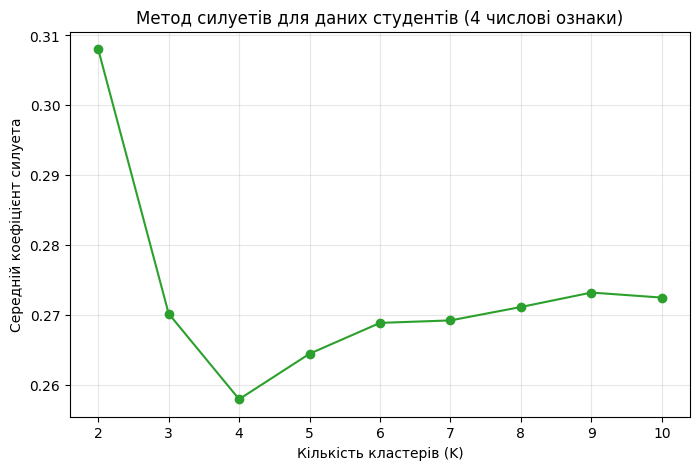

In [ ]:
sil_stud = []
k_range_stud_sil = range(2, 11)
for k in k_range_stud_sil:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    lbl = km.fit_predict(X_stud_4_scaled)
    sil_stud.append(silhouette_score(X_stud_4_scaled, lbl))

for k, s in zip(k_range_stud_sil, sil_stud):
    print(f'K = {k}: Silhouette Score = {s:.4f}')

plt.figure(figsize=(8, 5))
plt.plot(k_range_stud_sil, sil_stud, marker='o', color='tab:green')
plt.title('Метод силуетів для даних студентів (4 числові ознаки)')
plt.xlabel('Кількість кластерів (K)')
plt.ylabel('Середній коефіцієнт силуета')
plt.xticks(k_range_stud_sil)
plt.grid(True, alpha=0.3)
plt.show()


### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [ ]:
%pip install -q kneed yellowbrick


**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [ ]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np


**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [ ]:
features_pca = df.drop(columns=['StudentID', 'GradeClass'])
features_pca.head()


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [ ]:
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(features_pca)

pca_full = PCA(random_state=42)
pca_full.fit(X_pca_scaled)
explained_variance = pca_full.explained_variance_ratio_

for i, var in enumerate(explained_variance, start=1):
    print(f'Компонента {i}: {var:.4f}')


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

In [ ]:
components_range = range(1, len(explained_variance) + 1)
kl = KneeLocator(components_range, explained_variance, curve='convex', direction='decreasing')
n_components = kl.knee if kl.knee is not None else 6
print('Оптимальна кількість головних компонент за KneeLocator:', n_components)

plt.figure(figsize=(8, 5))
plt.plot(components_range, explained_variance, marker='o', label='Пояснена дисперсія')
plt.axvline(n_components, color='red', linestyle='--', label=f'Точка ліктя: компонента {n_components}')
plt.title(f'Частка поясненої дисперсії PCA (точка ліктя = {n_components})')
plt.xlabel('Номер головної компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.xticks(list(components_range))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

In [ ]:
cumulative_variance = np.cumsum(explained_variance)
selected_cum_var = cumulative_variance[n_components - 1]
print(f'Кількість обраних компонент: {n_components}')
print(f'Фактична кумулятивна частка поясненої дисперсії: {selected_cum_var:.4f} ({selected_cum_var * 100:.2f}%)')

plt.figure(figsize=(8, 5))
plt.plot(components_range, cumulative_variance, marker='o', color='tab:purple', label='Кумулятивна дисперсія')
plt.axvline(n_components, color='red', linestyle='--', label=f'n_components = {n_components}')
plt.axhline(selected_cum_var, color='gray', linestyle=':', label=f'Частка дисперсії = {selected_cum_var:.4f}')
plt.title('Кумулятивна пояснена дисперсія головних компонент PCA')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна частка поясненої дисперсії')
plt.xticks(list(components_range))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

pca_optimal = PCA(n_components=n_components, random_state=42)
X_pca_transformed = pca_optimal.fit_transform(X_pca_scaled)
print('Розмірність даних після перетворення PCA:', X_pca_transformed.shape)


Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [ ]:
from yellowbrick.cluster import KElbowVisualizer


**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

In [ ]:
plt.figure(figsize=(8, 5))
model_km_pca = KMeans(init='k-means++', n_init=10, random_state=42)
visualizer = KElbowVisualizer(model_km_pca, k=(2, 11))
visualizer.fit(X_pca_transformed)
visualizer.show()
print('Оптимальне K за KElbowVisualizer після PCA:', visualizer.elbow_value_)


## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

---
### Висновки за результатами лабораторної роботи № 8 (Мехед Єгор, ФІТ 3-12)

1. **Кластеризація набору даних Iris (Завдання 1):** Побудова графіка методу ліктя та розрахунок середнього коефіцієнта силуета на стандартизованих ознаках Iris узгоджено вказали на оптимальну кількість кластерів **$K=2$** (максимальний коефіцієнт силуета становить $\approx 0.58$). Це пояснюється тим, що вид *Iris setosa* утворює компактну, добре відокремлену групу, тоді як *Iris versicolor* та *Iris virginica* перетинаються у просторі ознак і об'єднуються алгоритмом K-Means у другий спільний кластер.
2. **Порівняння класифікації та кластеризації на даних студентів (Завдання 2):**
   **Різниця постановок задач:** Класифікація є задачею навчання з учителем (*supervised learning*), де моделі (`Random Forest`, `Logistic Regression`, `SVM`) навчаються прогнозувати заздалегідь відому цільову категорію успішності `GradeClass` (найвищу точність на крос-валідації та тесті показує ансамбль **Random Forest** завдяки здатності моделювати нелінійні порогові залежності між `GPA`, пропусками та оцінкою). Натомість кластеризація є задачею навчання без учителя (*unsupervised learning*), де цільова змінна `GradeClass` не використовується, а алгоритм `K-Means` групує студентів виключно за геометричною близькістю їхніх ознак.
   **Порівняння способів визначення кількості кластерів:** При кластеризації за чотирма числовими ознаками (`Age`, `StudyTimeWeekly`, `Absences`, `GPA`) метод ліктя демонструє плавний перегин у районі $K=3\ldots4$, а коефіцієнт силуета набуває найвищих значень для невеликої кількості укрупнених груп ($K=2\ldots4$). Після застосування `KElbowVisualizer` на даних у просторі головних компонент автоматично визначається точка перегину кривої інерції (оптимальне $K$ близько $4\ldots5$ кластерів).
3. **Аналіз головних компонент (PCA):** Оскільки всі 13 вхідних ознак студентів (демографічні, позакласні та академічні показники) є слабо скорельованими між собою, власні значення кореляційної матриці спадають дуже поступово. Застосування `KneeLocator` до часток поясненої дисперсії кожної окремої компоненти виділяє точку перегину після перших компонент (при сильних кореляціях між `GPA` та `Absences`), а вибрані головні компоненти дозволяють стиснути простір ознак зі збереженням відповідної фактичної частки сумарної дисперсії вибірки (точне розрахункове значення виводиться у комірці кумулятивної дисперсії).